In [1]:
import wot
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import scanpy as sc
from pathlib import Path
from collections import defaultdict
from scipy import sparse

import chronopack as cp


In [2]:
import os
from pathlib import Path

# Folder holding one sub-folder per experiment; see analyses/README.md.
DATA_DIR = Path(os.environ.get("CHRONOPACK_DATA_DIR", "../data"))
EXP_DIR = DATA_DIR / "thp1-k562-lps.hg38.rep"

## Waddington‑OT (Transport maps)
Following the official [WOT notebooks](https://github.com/broadinstitute/wot/tree/master/notebooks), we compute transport maps between successive time points.
Make sure `adata.obs['time']` (integer or float) exists and reflects the sampling time in *hours/days* used in the Seurat notebook.

In [3]:
adata = sc.read_h5ad(EXP_DIR / 'output/adata_full.chk0.h5ad')
adata_hvg = sc.read_h5ad(EXP_DIR / 'output/adata_hvg.chk0.h5ad')
adata.obs['time'] = pd.to_numeric(adata.obs['time'].astype(str))
adata_hvg.obs['time'] = pd.to_numeric(adata_hvg.obs['time'].astype(str))
adata_hvg.X = adata_hvg.layers['log1p']

adata_hvg_thp1 = adata_hvg[adata_hvg.obs['cell_type'] == 'THP1', :].copy()
adata_hvg_k562 = adata_hvg[adata_hvg.obs['cell_type'] == 'K562', :].copy()

wot_thp1 = cp.tl.get_trajectories(
    adata_hvg_thp1,
    tmap_dir=EXP_DIR / 'intmd/tmaps.THP1.SingleCell',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    attach_graph=False,
)

wot_k562 = cp.tl.get_trajectories(
    adata_hvg_k562,
    tmap_dir=EXP_DIR / 'intmd/tmaps.K562.SingleCell',
    ot_model_kwargs=dict(epsilon=0.05, lambda1=1, lambda2=50, growth_iters=3, day_field='time'),
    compute_transport_maps=True,
    transition_topk=30,
    symmetrize='maximum',
    attach_graph=False,
)


Built 11 transport matrices.
Built 11 transport matrices.


In [4]:
tmaps = {'THP1': wot_thp1['tmaps'], 'K562': wot_k562['tmaps']}
tmats = {'THP1': wot_thp1['tmats'], 'K562': wot_k562['tmats']}


# Construct forward transition kernel (+ pruned & symmetric variants)

In [5]:
T_pruned_thp1, T_sym_thp1 = wot_thp1['T_pruned'], wot_thp1['T_sym']
T_pruned_k562, T_sym_k562 = wot_k562['T_pruned'], wot_k562['T_sym']


In [6]:
# Transport maps were computed per cell type; combine them into one graph over all cells.
thp1_cells = adata_hvg_thp1.obs_names
k562_cells = adata_hvg_k562.obs_names

T_pruned = cp.tl.merge_trajectory_graphs(adata_hvg, [(thp1_cells, T_pruned_thp1), (k562_cells, T_pruned_k562)])

print(T_pruned_thp1.shape)
print(T_pruned_k562.shape)
print(T_pruned.shape)


(787, 787)
(3128, 3128)
(3915, 3915)


In [7]:
# Build the combined THP1+K562 graph from the two cell-type-specific WOT kernels.
T_sym = 0.5 * (T_pruned + T_pruned.T)

adata_hvg.obsp['ot_graph'] = T_sym
adata_hvg.uns['ot_graph'] = {
    'connectivities_key': 'ot_graph',
    'distances_key': 'ot_graph',
    'params': {'method': 'WOT_tmats_per_cell_type', 'top_k': 30, 'symmetric': 'mean'},
}

key = 'ot_umap'
sc.tl.umap(adata_hvg, neighbors_key='ot_graph', init_pos='spectral', copy=False, random_state=1, min_dist=1.5, spread=1.5, key_added=key)


In [8]:
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.obs = adata_hvg.obs.copy()

# Cluster trajectories

This also works, but to be fair this is particularly easy w/two distinct cell types

Terminal timepoint: 12 | n_terminal=298
Computed terminal distributions for time bin 11/12 (n=252)
Computed terminal distributions for time bin 10/12 (n=281)
Computed terminal distributions for time bin 9/12 (n=346)
Computed terminal distributions for time bin 8/12 (n=360)
Computed terminal distributions for time bin 7/12 (n=403)
Computed terminal distributions for time bin 6/12 (n=302)
Computed terminal distributions for time bin 5/12 (n=291)
Computed terminal distributions for time bin 4/12 (n=297)
Computed terminal distributions for time bin 3/12 (n=319)
Computed terminal distributions for time bin 2/12 (n=429)
Computed terminal distributions for time bin 1/12 (n=337)
Stored adata.obsm['terminal_cell_dist'] with shape (3915, 298) (sparse nnz=709702)


/new-stg/home/alex/tmp/ChronoPack/src/chronopack/tl/_trajectories.py:610: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  _scanpy().tl.leiden(


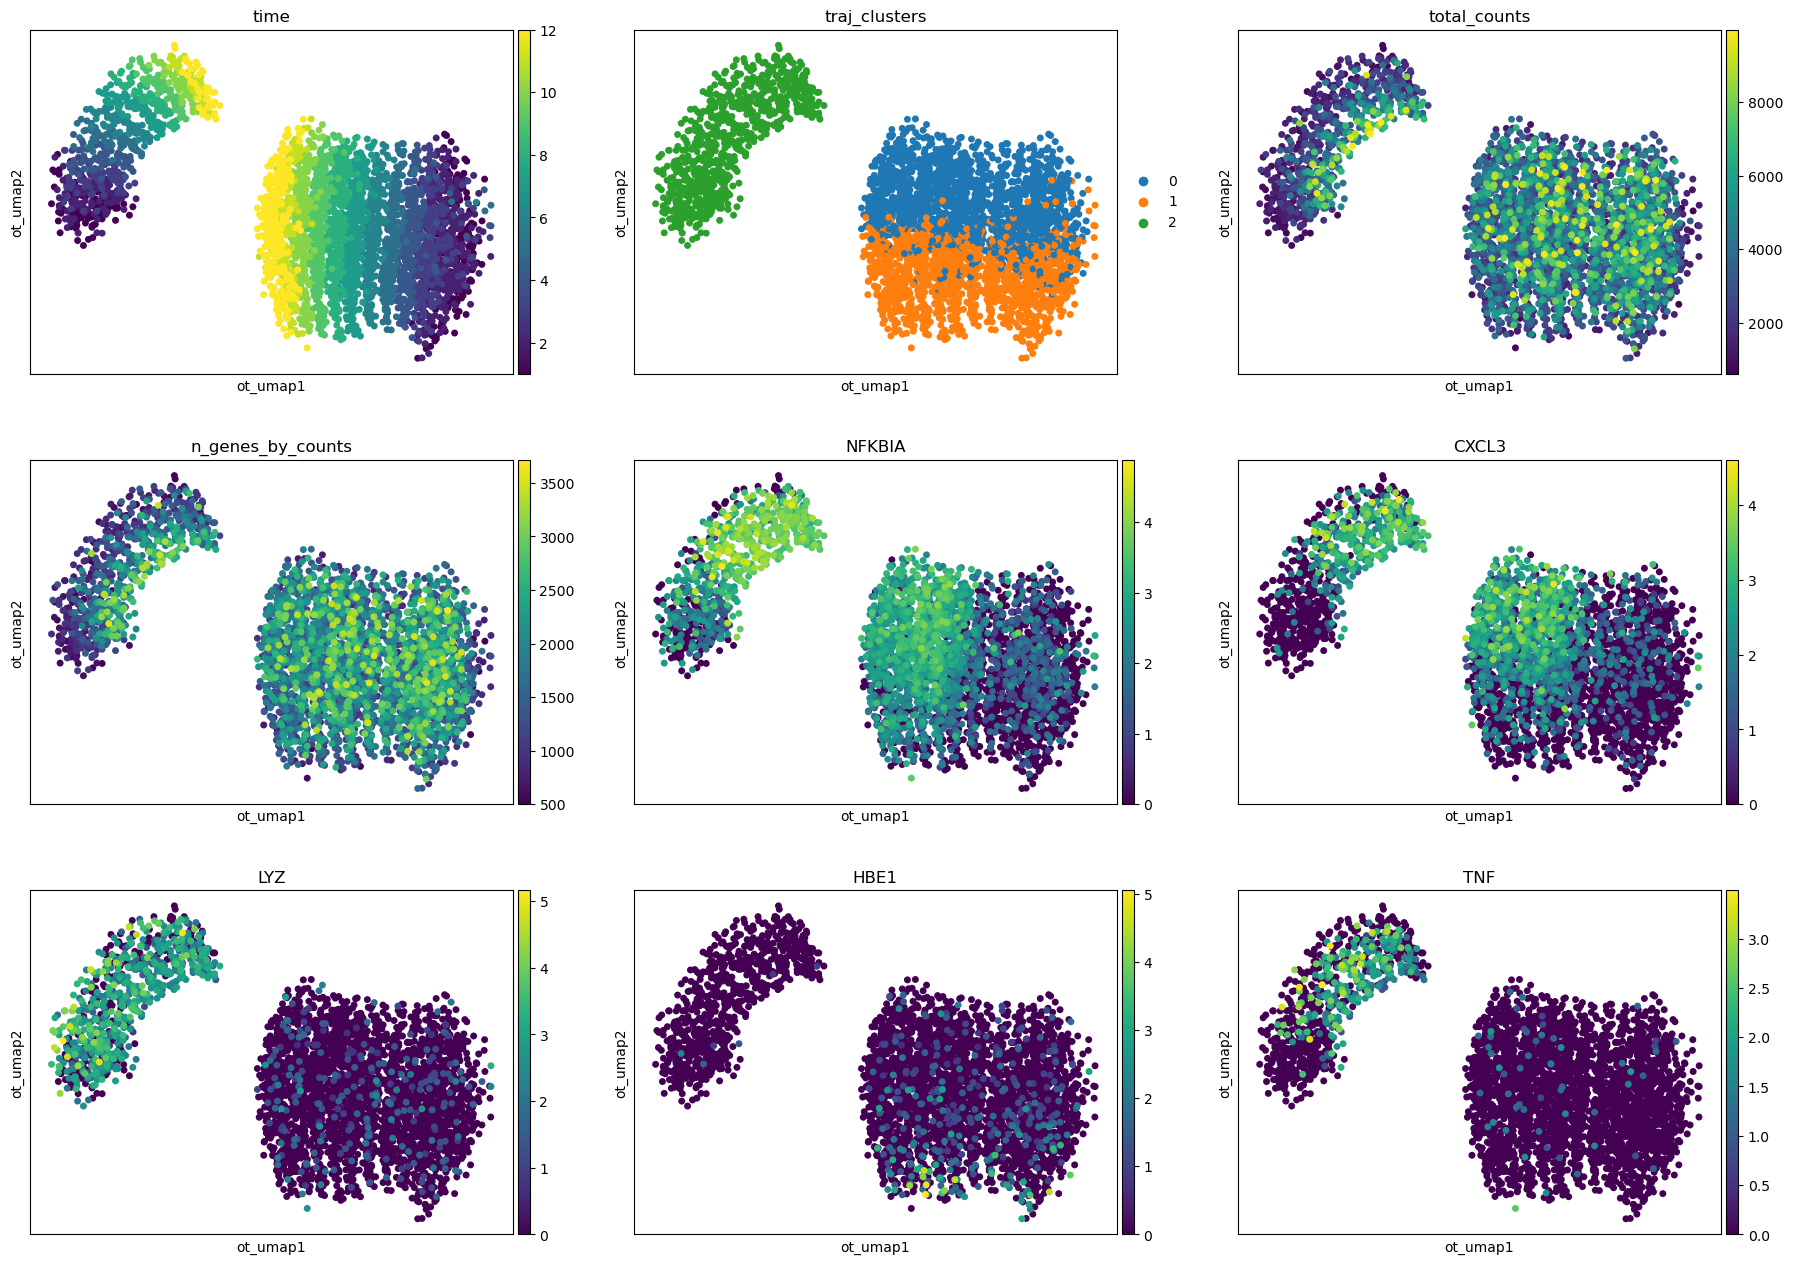

In [9]:
# Final trajectory clustering: terminal-fate-distance graph, resolution 0.6.
# These traj_clusters are propagated to the saved AnnData objects and used downstream.
S = cp.tl.cluster_cells_to_trajectories(
    adata_hvg,
    T_pruned,
    cluster_key="traj_clusters",
    resolution=0.6,
    graph_topk=500,
    random_state=0,
)
sc.pl.embedding(
    adata_hvg,
    basis="ot_umap",
    color=["time", "traj_clusters", "total_counts", "n_genes_by_counts", "NFKBIA", "CXCL3", "LYZ", "HBE1", "TNF"],
    ncols=3,
    cmap="viridis",
    size=100,
)


# Calculate terminal fates & trajectory cluster mass retention

(<Figure size 500x450 with 8 Axes>, array([[<Axes: title={'center': 'Fate prob: 0'}, xlabel='ot_umap1', ylabel='ot_umap2'>,
        <Axes: title={'center': 'Fate prob: 1'}, xlabel='ot_umap1', ylabel='ot_umap2'>],
       [<Axes: title={'center': 'Fate entropy (norm)'}, xlabel='ot_umap1', ylabel='ot_umap2'>,
        <Axes: title={'center': 'Fate maxprob'}, xlabel='ot_umap1', ylabel='ot_umap2'>]],
      dtype=object))

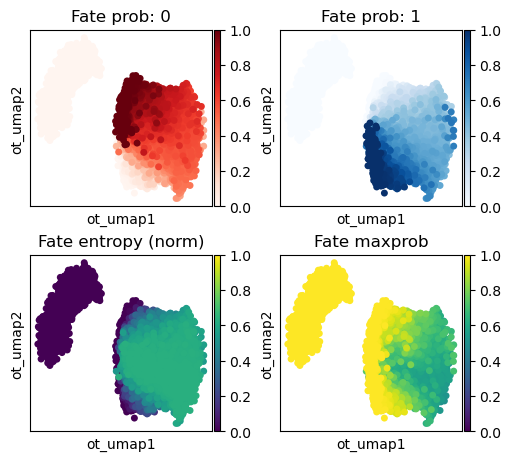

In [10]:
F, fate_names = cp.tl.compute_terminal_fate_probabilities(adata_hvg, terminal_cluster_key="traj_clusters", out_key="terminal_fate_probs_traj")
cp.pl.cell_trajectories.fate_probabilities(adata_hvg, embedding_basis="ot_umap", size=100)

/new-stg/home/alex/miniconda3/envs/chronopack-install-test/lib/python3.11/site-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


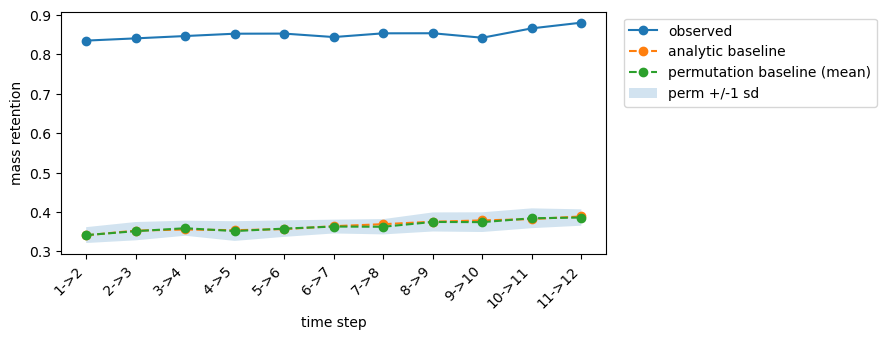

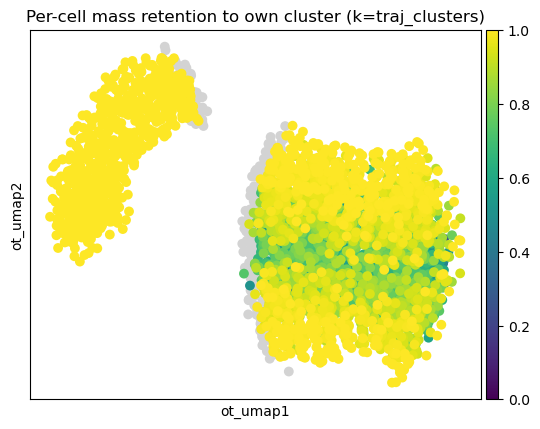

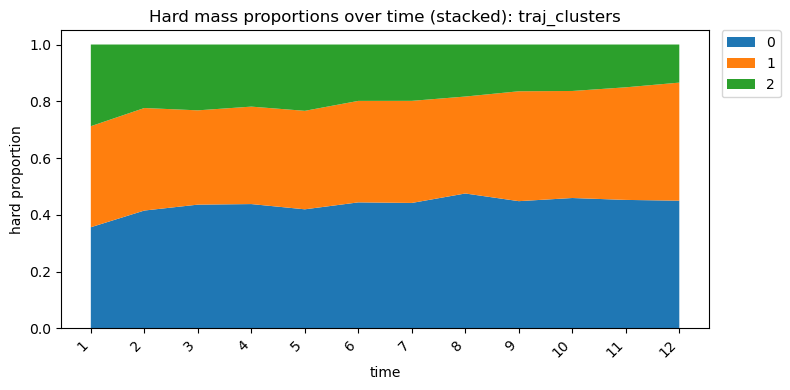

In [11]:
out = cp.pl.cell_trajectories.mass_retention(adata_hvg, S=T_pruned, 
                                    cluster_key="traj_clusters", 
                                    n_reps=50, clusters_to_plot=["0","1"], 
                                    embedding_basis="ot_umap", size=200)
cp.pl.cell_trajectories.proportions_over_time(adata_hvg, cluster_key="traj_clusters")


In [12]:
adata.obs = adata_hvg.obs.copy()
adata.obsm = adata_hvg.obsm.copy()
adata.obsp = adata_hvg.obsp.copy()
adata.uns = adata_hvg.uns.copy()

adata.write_h5ad(EXP_DIR / 'output/adata_full.chk1.h5ad')
adata_hvg.write_h5ad(EXP_DIR / 'output/adata_hvg.chk1.h5ad')